# Model and feature qualification (0A and 0B)

Before extraction, 0A checks pinned decision models and encoders on real hardware. After extraction, core 0B tests the predictor runtimes and representative full folds using the saved features. Group C has additional checks once its Strands v1 inputs exist. Its nine C0 training pilots are listed in the study audit.

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
import pandas as pd
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.visualize import figures, style
style.apply()

NOTEBOOK = "general/3_model_and_feature_qualification"
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. Scope and provenance")
display_json("Notebook execution identity", provenance())

## 0A runtime gates and footprint

Every gate is read from a local receipt; a white square means no receipt was found here, not a failed model. The right panels come from the same contract run on one B200.

model_id,model,pin,kind,known_answer,robustness,token_audit,accepted,accepted_utc,gpu_name,peak_gpu_gb,load_seconds,contract_seconds,live_requests,configured,staged_receipt,full_bank_tokens,bounded_runtime,semantic_review,complete_feature_datasets,observed_utc,source,source_sha256,staged_manifest
jev,jev-1.14.0,1.14.0,hosted,not_applicable,review,not_applicable,unknown,None,None,NaN,NaN,NaN,NaN,observed,not_applicable,not_applicable,review,unknown,not assessed here,2026-10-29T21:00:00.183761+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\01_exp0a\manifests\before_extraction\jev_smoke.json,6226659b7be4bdf23cdf0c8365978c40d70dea1bc254aff36fceace6d32487c3,None
liquid,LiquidAI/d1-3B,051bcc464b01b9f92942b364d9586b0ef5912432,open,observed,observed,observed,observed,2026-10-30T13:23:17.387332+00:00,NVIDIA B200,6.538566,4.297721,49.701576,102.0,observed,unknown,observed,observed,review,not assessed here,2026-10-30T08:21:14.509740+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\01_exp0a\manifests\before_extraction\gpu_contracts\liquid_9ec245d2a03d40f9bca2463e96fcd409.json,414b11f1c57492d80fbaf8fac85771a92d70b9c81793e29a84eb0a8e5895b4f5,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\liquid\_JEVPFN_CHECKPOINT.json
liquid_lfm3,LiquidAI/d1-2B,cfe5760ff5d5998f91d9ac56bd4b2dbd96996d41,open,observed,observed,observed,observed,2026-10-30T13:23:17.575867+00:00,NVIDIA B200,4.112390,16.702619,60.828091,102.0,observed,unknown,observed,observed,review,not assessed here,2026-10-30T11:39:19.778468+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\01_exp0a\manifests\before_extraction\gpu_contracts\liquid_lfm3_fb5afa385b7948dfab5fb5352524ba42.json,f87cbf10999bb7c3a2b7b027822a128b30ddf8fd684b7a9feec5116ffa650f43,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\liquid_lfm3\_JEVPFN_CHECKPOINT.json
perplexity,perplexity-ai/pplx-decider-v1.1-27b,14c9d90137962d300f3de95633f7b6535e80c5ce,open,observed,observed,observed,observed,2026-10-30T13:23:17.448997+00:00,NVIDIA B200,52.857277,31.841778,141.752177,106.0,observed,unknown,observed,observed,review,not assessed here,2026-10-30T08:41:41.848037+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\01_exp0a\manifests\before_extraction\gpu_contracts\perplexity_db1723afd7f846dc8f52dba49770fade.json,f9be1fe46c0e0e17f249829692e60d5463b32fe0942d52fc718652b228d2a504,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\perplexity\_JEVPFN_CHECKPOINT.json
cloudflare,Cloudflare/clef-flash,8b2e5fd17c09fd49bc2880b805d5323ec7ff4ff3,open,observed,observed,observed,observed,2026-10-30T13:23:17.474003+00:00,NVIDIA B200,19.913589,12.071956,64.333045,106.0,observed,unknown,observed,observed,review,not assessed here,2026-10-30T08:49:56.555572+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\01_exp0a\manifests\before_extraction\gpu_contracts\cloudflare_b6122293809044ba9d602c99595cc73f.json,693b3f8159968eac8e32de9d0d2acbb194b7beff53e58c24173ab8fafce8bad5,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\cloudflare\_JEVPFN_CHECKPOINT.json
intern,internlm/Intern-Decision-4B,0e5e6aa7d6d750e2b1504ba11a8136cb58aeb3cd,open,observed,observed,observed,observed,2026-10-30T13:23:17.485489+00:00,NVIDIA B200,10.032857,23.103771,64.141661,102.0,observed,unknown,observed,observed,review,not assessed here,2026-10-30T09:01:00.375521+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\01_exp0a\manifests\before_extraction\gpu_contracts\intern_d3fea05f63544011859d6a99e819cf50.json,efbbd63f50ecfe417db34f67c301cfe0ac69453efae3f4dd4a8959831f29f8ec,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\intern\_JEVPFN_CHECKPOINT.json
strands,StrandsAgents/strands-decider-2B-qwen3.5-v1-2610,216d1ccb46a9e9b036eb9187b248

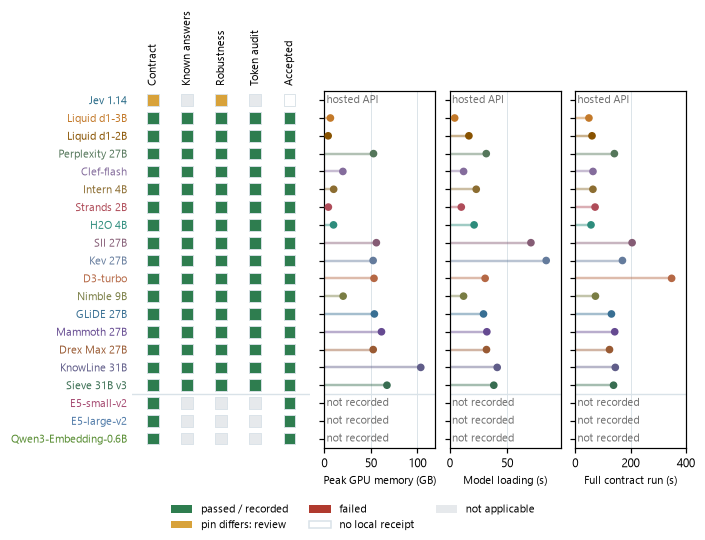

In [2]:
report_section("2. 0A runtime evidence")
from src.evaluation.notebook_evidence import local_runtime_evidence
from src.visualize.research import runtime_evidence_figure
from src.utils.config import load_yaml
evidence, token_scope = local_runtime_evidence()
display_table("Runtime pins, receipt provenance and recorded status", evidence, preview_rows=20)
display_json("Exact token audit scope", token_scope)
record(load_yaml("experiment_0/debug"), "Configured extraction acceptance gates")
fig, name, caption = runtime_evidence_figure(evidence)
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)

## Historical 0A sensitivity probes

Three real inputs (one per task) rerun under controlled changes to the input: a paraphrase, unrelated context, an inserted instruction and, for multiclass, reversed options. These dated probes informed qualification; they are not the larger A2 stability study and were never used to choose prompts.

provider,recorded_model,recorded_revision,source_sha256,probe,total_variation_from_base,same_top_option,maximum_probability_change,expected_direction_change,created_utc,variant,dataset_id
jev,jev-1.13.0,None,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_BIN_TEXT_FAKE_JOB_POSTING__base,0.00,True,0.00,NaN,2026-10-29T21:01:34.592944+00:00,base,BIN_TEXT_FAKE_JOB_POSTING
jev,jev-1.13.0,None,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_BIN_TEXT_FAKE_JOB_POSTING__paraphrase,0.03,True,0.03,NaN,2026-10-29T21:01:34.592944+00:00,paraphrase,BIN_TEXT_FAKE_JOB_POSTING
jev,jev-1.13.0,None,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_BIN_TEXT_FAKE_JOB_POSTING__irrelevant_context,0.12,True,0.12,NaN,2026-10-29T21:01:34.592944+00:00,irrelevant_context,BIN_TEXT_FAKE_JOB_POSTING
jev,jev-1.13.0,None,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_BIN_TEXT_FAKE_JOB_POSTING__embedded_instruction,0.51,False,0.51,NaN,2026-10-29T21:01:34.592944+00:00,embedded_instruction,BIN_TEXT_FAKE_JOB_POSTING
jev,jev-1.13.0,None,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_MUL_TEXT_DATA_SCIENTIST_SALARY__base,0.00,True,0.00,NaN,2026-10-29T21:01:34.592944+00:00,base,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,jev-1.13.0,None,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_MUL_TEXT_DATA_SCIENTIST_SALARY__paraphrase,0.05,True,0.05,NaN,2026-10-29T21:01:34.592944+00:00,paraphrase,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,jev-1.13.0,None,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_MUL_TEXT_DATA_SCIENTIST_SALARY__irrelevant_context,0.09,True,0.07,NaN,2026-10-29T21:01:34.592944+00:00,irrelevant_context,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,jev-1.13.0,None,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_MUL_TEXT_DATA_SCIENTIST_SALARY__embedded_instruction,0.16,True,0.14,NaN,2026-10-29T21:01:34.592944+00:00,embedded_instruction,MUL_TEXT_DATA_SCIENTIST_SALARY
provider,recorded_model,recorded_revision,source_sha256,probe,total_variation_from_base,same_top_option,maximum_probability_change,expected_direction_change,created_utc,variant,dataset_id
jev,jev-1.13.0,None,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_BIN_TEXT_FAKE_JOB_POSTING__base,0.000000,True,0.000000,NaN,2026-10-29T21:01:34.592944+00:00,base,BIN_TEXT_FAKE_JOB_POSTING


path,sha256,created_utc,status,scope,input_sets
jev_dataset_robustness.json,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,2026-10-29T21:01:34.592944+00:00,jev_dataset_robustness_requires_review,selected diagnostic inputs; not a population estimate or current-code acceptance,"[""0a548be2ac252daf7d050ef70f4da69f15f3207b23f67529be76dbe877d3d165"", ""7b5b4b36dcb7e9fae1737d6d092384fafb313909347626bfe34ea5844ebf4266"", ""e2916a682f8f80b17c09b131469afea1655ed61337c2e0e570fec8d49d4af4ad""]"
cloudflare_b6122293809044ba9d602c99595cc73f.json,693b3f8159968eac8e32de9d0d2acbb194b7beff53e58c24173ab8fafce8bad5,2026-10-30T08:49:56.555572+00:00,gpu_contracts_passed_requires_review,selected diagnostic inputs; not a population estimate or current-code acceptance,[]
decision3_50c8e817a95848f79089f3deb516e1f3.json,89206054b8df83fd566cbd29e11b8009be79947fc9bc9ead7c70f1eb02a570e9,2026-10-30T11:12:47.808586+00:00,gpu_contracts_passed_requires_review,selected diagnostic inputs; not a population estimate or current-code acceptance,[]
drex_max_38dcc0c217244c4a8eb9e5d6eff48ae7.json,528de91cacb67040f6e026182dcc2edff6d72c4e32b3a18c4cf1642138025f39,2026-11-24T10:59:01.563776+00:00,gpu_contracts_passed_requires_review,selected diagnostic inputs; not a population estimate or current-code acceptance,[]
glide_d06194d9798d49ddb295e1b6fb04c4e3.json,b70d0cfae60c5bcba8800e13042ede585aef91868ff344025f403eb101574e56,2026-11-24T11:18:35.190283+00:00,gpu_contracts_passed_requires_review,selected diagnostic inputs; not a population estimate or current-code acceptance,[]
h2o_ab27555dcd1d45fca116296f9e2efd80.json,55c68a79746c516d05b4570316daab7d29ed901de113d10344a1531f7b6f1762,2026-10-30T09:14:37.509657+00:00,gpu_contracts_passed_requires_review,selected diagnostic inputs; not a population estimate or current-code acceptance,[]
intern_d3fea05f63544011859d6a99e819cf50.json,efbbd63f50ecfe417db34f67c301cfe0ac69453efae3f4dd4a8959831f29f8ec,2026-10-30T09:01:00.375521+00:00,gpu_contracts_passed_requires_review,selected diagnostic inputs; not a population estimate or current-code acceptance,[]
kev_c6e81868044b49cea161086928788ed7.json,0dfe0c7bb6e2f1b740a7e54fa393c10c96545ffc3ee8a0b34802b87db5802fe3,2026-10-30T10:30:38.201863+00:00,gpu_contracts_passed_requires_review,selected diagnostic inputs; not a population estimate or current-code acceptance,[]
path,sha256,created_utc,status,scope,input_sets
jev_dataset_robustness.json,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,2026-10-29T21:01:34.592944+00:00,jev_dataset_robustness_requires_review,selected diagnostic inputs; not a population estimate or current-code acceptance,"[""0a548be2ac252daf7d050ef70f4da69f15f3207b23f67529be76dbe877d3d165"", ""7b5b4b36dcb7e9fae1737d6d092384fafb313909347626bfe34ea5844ebf4266"", ""e2916a682f8f80b17c09b131469afea1655ed61337c2e0e570fec8d49d4af4ad""]"


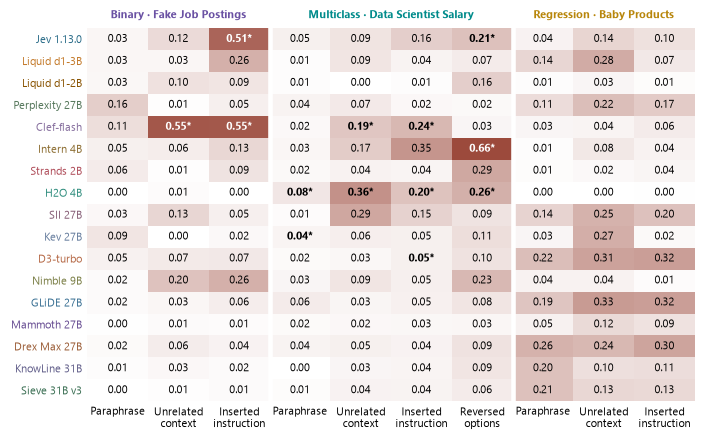

In [3]:
report_section("3. Historical 0A sensitivity probes")
from src.evaluation.robustness_export import historical_tables
from src.visualize.research import robustness_matrix_figure
historical = historical_tables()
changes = historical["historical_0a"]
if changes.empty:
    print("No historical 0A receipts are available locally.")
else:
    display_table("Every historical 0A comparison", changes)
    display_table("Dated receipts (file name and SHA-256)", historical["historical_0a_sources"])
    for fig, name, caption in robustness_matrix_figure(changes):
        save(fig, name, caption=caption)
        display_local(fig)
        plt.close(fig)

## 0B predictor contracts and full-fold profiles

Each of the seven fixed predictors and three native-text systems needs a passing synthetic contract on VSC and passing one-outer-fold profiles on real data for every arm family it serves, with the same runtime. The Kumo override profile is the widest Kumo arm, for which the 500-column default recipe is widened.

In [4]:
report_section("4. 0B predictor contracts and full-fold profiles")
from src.evaluation.notebook_study import predictor_evidence, profile_evidence
from src.evaluation.campaign import benchmark_plan
from src.evaluation.benchmark_export import cohort_name
from src.evaluation.qualification import kumo_override_arm
from src.visualize.study import qualification_figure
cohort = cohort_name()
predictors = predictor_evidence(cohort=cohort)
profiles = profile_evidence(predictors, cohort=cohort)
display_table("Predictor contract records", predictors.drop(columns=["configured_packages"]), preview_rows=10)
display_table("Required and passed full-fold profiles per arm family", profiles, preview_rows=12)
override = kumo_override_arm(benchmark_plan(cohort=cohort))
record({k: override[k] for k in ("dataset_id", "phase", "feature_set", "predictor_columns")} if override else None, "Kumo override profile arm")
if predictors.contract_passed.any() or profiles.passed.gt(0).any():
    fig, name, caption = qualification_figure(predictors, profiles)
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
else:
    print(f"Waiting for 0B evidence: no predictor contract or profile for the current evaluation identity is held locally "
          f"({int(profiles.required.sum())} profiles required).")

model,decision_cohort,contract_status,current_evaluation_identity,contract_passed,profiles_passed,profiles_required,full_fold_profile,source
catboost,open_weight,predictor_contracts_passed_requires_full_fold_profile,False,False,0,29,False,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\03_exp0b\manifests\after_extraction\predictor_catboost_b53b3a37d1984c90b6c38af4f22d9137.json
tabpfn_3_5,open_weight,not found locally,None,False,0,29,False,None
tabicl_v2,open_weight,not found locally,None,False,0,29,False,None
limix_2,open_weight,not found locally,None,False,0,29,False,None
kumo_tabular,open_weight,not found locally,None,False,0,29,False,None
linear,open_weight,predictor_contracts_passed_requires_full_fold_profile,False,False,0,64,False,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\03_exp0b\manifests\after_extraction\predictor_linear_fdf4d950a67643feaa90225767917547.json
lightgbm,open_weight,not found locally,None,False,0,29,False,None
tabstar,open_weight,not found locally,None,False,0,4,False,None
contexttab,open_weight,not found locally,None,False,0,4,False,None
ag_mm,open_weight,not found locally,None,False,0,4,False,None


model,family,required,passed
ag_mm,native,4,0
catboost,TAR,8,0
catboost,classifier,4,0
catboost,column refit,1,0
catboost,decision,4,0
catboost,decision+frozen,4,0
catboost,frozen,4,0
catboost,training size,4,0
contexttab,native,4,0
kumo_tabular,Kumo override,1,0


Waiting for 0B evidence: no predictor contract or profile for the current evaluation identity is held locally (250 profiles required).


## 0B feature identity and leakage screen

The 0B report checks complete feature identities, missingness, fold-local PCA/TAR preparation and leakage screens per dataset before any benchmark fit.

In [5]:
report_section("5. 0B feature identity and leakage screen")
from src.utils import paths
reports = sorted(paths.phase_path("experiment_0", "manifests", "after_extraction").glob("report_*.json"))
print("0B report:", [p.name for p in reports] if reports else "waiting for the 0B report JSON (not held locally).")

0B report: waiting for the 0B report JSON (not held locally).


## Complete report

In [6]:
finish_report(NOTEBOOK, save.summary() + "\nOnly saved receipts were analysed; no inference, model training or live VSC changes were performed.")

general/3_model_and_feature_qualification

1. Scope and provenance


Notebook execution identity
{
  "code_sha256": "8b4d9540fb90939d06c1177e768d032c9866801857bd06cfd36cb4fa3aea5040",
  "git_head": "e5d935fe73a631187c6d40435fbeb13c6743c494",
  "git_dirty": true,
  "tfm_library_pin": "4574eea0c2ce6646b5d2e9c7f53a6ef3882c368c dm-library (remotes/origin/HEAD)\n 248f137046487e0d57360abba1e060420ae54e1a tfm-library (remotes/origin/HEAD)\n 2208cf68d6351eff2cb0ddb5a9eb1d822523457b vsc-library (heads/main-8-g2208cf6)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.4",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


2. 0A runtime evidence


Runtime pins, receipt provenance and recorded status
            model_id                                            model                                      pin    kind   known_answer     robustness    token_audit accepted                     accepted_utc    gpu_name  peak_gpu_gb  l